# Task 2 - Customer Segmentation
**Elevvo ML Internship - Level 1**

Goal: group mall customers into segments based on annual income and spending score with K-Means, choose the best number of clusters, and compare with DBSCAN.

Dataset: [Mall Customer Segmentation (Kaggle)](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) - put `Mall_Customers.csv` in the same folder as this notebook (in Colab, upload it with the Files panel).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

In [2]:
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich import box

console = Console()
GREEN, CYAN, AMBER = '#33ff66', '#00e5ff', '#ffb000'
BORDER = '#15803d'  # darker green so borders stay visible on light backgrounds (e.g. GitHub)
PALETTE = [GREEN, CYAN, AMBER, '#ff4fd8', '#b388ff', '#ff6e6e', '#ffffff']

plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'monospace', 'axes.edgecolor': GREEN, 'axes.labelcolor': GREEN,
    'xtick.color': GREEN, 'ytick.color': GREEN, 'axes.titlecolor': GREEN,
    'axes.grid': True, 'grid.color': '#1f3d1f', 'grid.linestyle': ':',
})

def term_table(df, title, index=True):
    t = Table(title=f'> {title}', title_justify='left', title_style=f'bold {GREEN}',
              box=box.SQUARE, border_style=BORDER, header_style=f'bold {CYAN}')
    if index:
        t.add_column(str(df.index.name or ''), style=AMBER)
    for col in df.columns:
        t.add_column(str(col), justify='right', style=GREEN)
    for idx, *row in df.itertuples():
        values = [f'{v:,.3f}' if isinstance(v, float) else str(v) for v in row]
        t.add_row(*([str(idx)] if index else []), *values)
    console.print(t)

def term_panel(title, lines):
    body = '\n'.join(f'[{GREEN}]$[/] {line}' for line in lines)
    console.print(Panel(body, title=f'[bold {GREEN}]{title}', title_align='left',
                        border_style=BORDER, box=box.SQUARE, expand=False))

## 1. Load and explore the data

In [3]:
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'})
term_panel('DATASET LOADED', [f'rows    : {df.shape[0]}', f'columns : {df.shape[1]}',
                              f'missing : {df.isnull().sum().sum()}', f'duplicates : {df.duplicated().sum()}'])
term_table(df.head(5).set_index('CustomerID'), 'FIRST 5 CUSTOMERS')

┌─ DATASET LOADED ─┐
│ $ rows    : 200  │
│ $ columns : 5    │
│ $ missing : 0    │
│ $ duplicates : 0 │
└──────────────────┘

> FIRST 5 CUSTOMERS                              
┌────────────┬────────┬─────┬────────┬──────────┐
│ CustomerID │ Gender │ Age │ Income │ Spending │
├────────────┼────────┼─────┼────────┼──────────┤
│ 1          │   Male │  19 │     15 │       39 │
│ 2          │   Male │  21 │     15 │       81 │
│ 3          │ Female │  20 │     16 │        6 │
│ 4          │ Female │  23 │     16 │       77 │
│ 5          │ Female │  31 │     17 │       40 │
└────────────┴────────┴─────┴────────┴──────────┘

In [4]:
term_table(df.drop(columns='CustomerID').describe().T.round(2), 'NUMERIC SUMMARY')
term_table(df['Gender'].value_counts().to_frame('customers'), 'GENDER')

> NUMERIC SUMMARY                                                                     
┌──────────┬─────────┬────────┬────────┬────────┬────────┬────────┬────────┬─────────┐
│          │   count │   mean │    std │    min │    25% │    50% │    75% │     max │
├──────────┼─────────┼────────┼────────┼────────┼────────┼────────┼────────┼─────────┤
│ Age      │ 200.000 │ 38.850 │ 13.970 │ 18.000 │ 28.750 │ 36.000 │ 49.000 │  70.000 │
│ Income   │ 200.000 │ 60.560 │ 26.260 │ 15.000 │ 41.500 │ 61.500 │ 78.000 │ 137.000 │
│ Spending │ 200.000 │ 50.200 │ 25.820 │  1.000 │ 34.750 │ 50.000 │ 73.000 │  99.000 │
└──────────┴─────────┴────────┴────────┴────────┴────────┴────────┴────────┴─────────┘

> GENDER              
┌────────┬───────────┐
│ Gender │ customers │
├────────┼───────────┤
│ Female │       112 │
│ Male   │        88 │
└────────┴───────────┘

## 2. Visual exploration

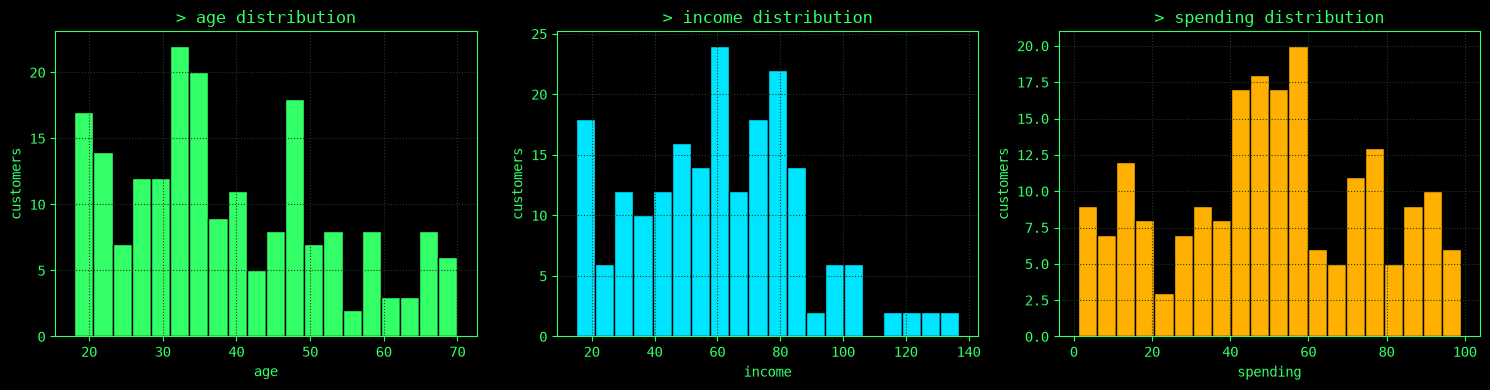

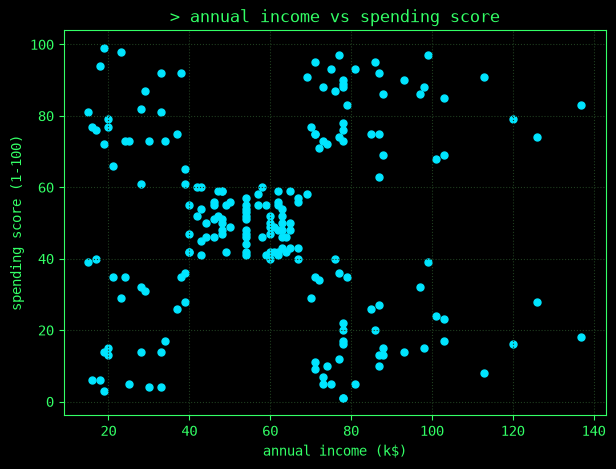

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ['Age', 'Income', 'Spending'], [GREEN, CYAN, AMBER]):
    ax.hist(df[col], bins=20, color=color, edgecolor='black')
    ax.set(title=f'> {col.lower()} distribution', xlabel=col.lower(), ylabel='customers')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(df['Income'], df['Spending'], color=CYAN, s=25)
plt.title('> annual income vs spending score')
plt.xlabel('annual income (k$)')
plt.ylabel('spending score (1-100)')
plt.show()

## 3. Scaling
K-Means uses distances, so both features are scaled to the same range (mean 0, standard deviation 1).

In [6]:
X = df[['Income', 'Spending']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
term_table(pd.DataFrame(X_scaled, columns=X.columns).describe().T[['mean', 'std', 'min', 'max']].round(2), 'AFTER SCALING')

> AFTER SCALING                               
┌──────────┬────────┬───────┬────────┬───────┐
│          │   mean │   std │    min │   max │
├──────────┼────────┼───────┼────────┼───────┤
│ Income   │ -0.000 │ 1.000 │ -1.740 │ 2.920 │
│ Spending │ -0.000 │ 1.000 │ -1.910 │ 1.890 │
└──────────┴────────┴───────┴────────┴───────┘

## 4. Finding the best number of clusters
- **Elbow method:** inertia (how tight the clusters are) drops as k grows; the bend in the curve is a good k.
- **Silhouette score:** how well each customer fits its own cluster versus the next one (higher is better).

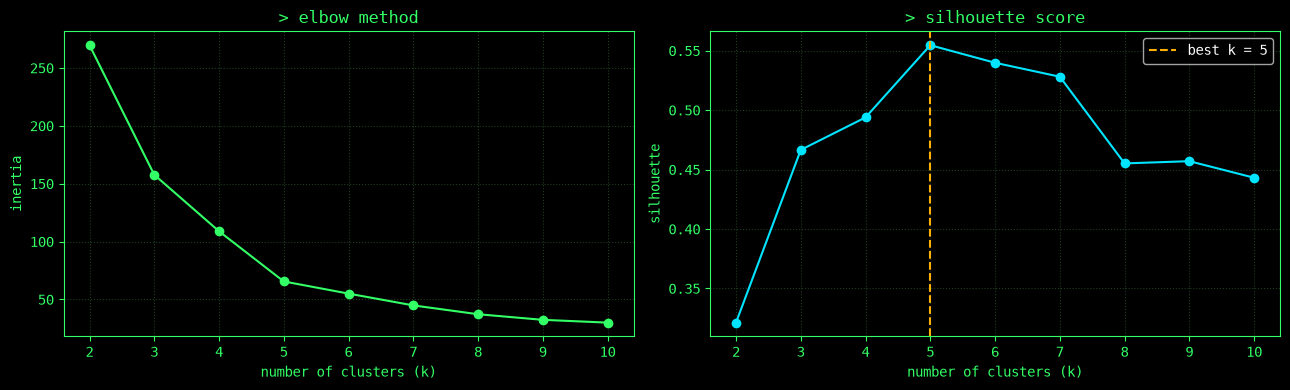

> K SEARCH                   
┌────┬─────────┬────────────┐
│ k  │ inertia │ silhouette │
├────┼─────────┼────────────┤
│ 2  │ 269.691 │      0.321 │
│ 3  │ 157.704 │      0.467 │
│ 4  │ 108.921 │      0.494 │
│ 5  │  65.568 │      0.555 │
│ 6  │  55.057 │      0.540 │
│ 7  │  44.865 │      0.528 │
│ 8  │  37.228 │      0.455 │
│ 9  │  32.392 │      0.457 │
│ 10 │  29.982 │      0.443 │
└────┴─────────┴────────────┘

┌─ BEST K ───────────────────┐
│ $ k = 5 (silhouette 0.555) │
└────────────────────────────┘

In [7]:
scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    scores.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X_scaled, km.labels_)})
scores = pd.DataFrame(scores).set_index('k')
best_k = int(scores['silhouette'].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(scores.index, scores['inertia'], marker='o', color=GREEN)
axes[0].set(title='> elbow method', xlabel='number of clusters (k)', ylabel='inertia')
axes[1].plot(scores.index, scores['silhouette'], marker='o', color=CYAN)
axes[1].axvline(best_k, color=AMBER, linestyle='--', label=f'best k = {best_k}')
axes[1].set(title='> silhouette score', xlabel='number of clusters (k)', ylabel='silhouette')
axes[1].legend()
plt.tight_layout()
plt.show()

term_table(scores, 'K SEARCH')
term_panel('BEST K', [f'k = {best_k} (silhouette {scores.loc[best_k, "silhouette"]:.3f})'])

## 5. K-Means clustering

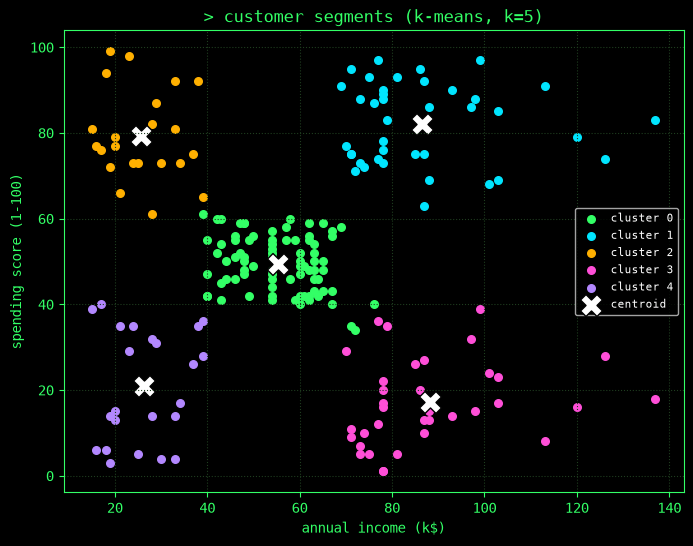

In [8]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=['Income', 'Spending'])

plt.figure(figsize=(8, 6))
for c in range(best_k):
    group = df[df['Cluster'] == c]
    plt.scatter(group['Income'], group['Spending'], s=30, color=PALETTE[c], label=f'cluster {c}')
plt.scatter(centers['Income'], centers['Spending'], s=250, marker='X', color='white', edgecolor='black', label='centroid')
plt.title(f'> customer segments (k-means, k={best_k})')
plt.xlabel('annual income (k$)')
plt.ylabel('spending score (1-100)')
plt.legend(fontsize=8)
plt.show()

## 6. Bonus: average spending per cluster
Each segment gets a name from how its income and spending compare to the average customer.

In [9]:
profile = df.groupby('Cluster').agg(
    customers=('CustomerID', 'count'),
    avg_income=('Income', 'mean'),
    avg_spending=('Spending', 'mean'),
    avg_age=('Age', 'mean'),
)

def level(value, overall):
    if value > overall * 1.2:
        return 'high'
    if value < overall * 0.8:
        return 'low'
    return 'average'

profile['segment'] = [f'{level(r.avg_income, df.Income.mean())} income / {level(r.avg_spending, df.Spending.mean())} spending'
                      for r in profile.itertuples()]
profile = profile.sort_values('avg_spending', ascending=False)
term_table(profile, 'CLUSTER PROFILES')

> CLUSTER PROFILES                                                                               
┌─────────┬───────────┬────────────┬──────────────┬─────────┬───────────────────────────────────┐
│ Cluster │ customers │ avg_income │ avg_spending │ avg_age │                           segment │
├─────────┼───────────┼────────────┼──────────────┼─────────┼───────────────────────────────────┤
│ 1       │        39 │     86.538 │       82.128 │  32.692 │       high income / high spending │
│ 2       │        22 │     25.727 │       79.364 │  25.273 │        low income / high spending │
│ 0       │        81 │     55.296 │       49.519 │  42.716 │ average income / average spending │
│ 4       │        23 │     26.304 │       20.913 │  45.217 │         low income / low spending │
│ 3       │        35 │     88.200 │       17.114 │  41.114 │        high income / low spending │
└─────────┴───────────┴────────────┴──────────────┴─────────┴───────────────────────────────────┘

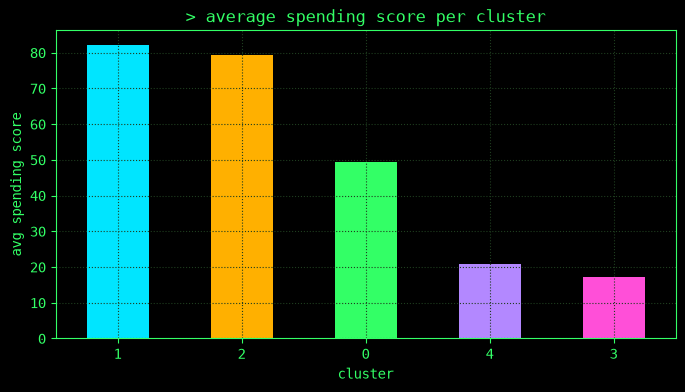

In [10]:
profile['avg_spending'].plot(kind='bar', figsize=(8, 4), color=[PALETTE[c] for c in profile.index], title='> average spending score per cluster')
plt.xlabel('cluster')
plt.ylabel('avg spending score')
plt.xticks(rotation=0)
plt.show()

## 7. Bonus: DBSCAN
DBSCAN groups customers by density instead of a fixed k, and marks outliers as noise (label -1).

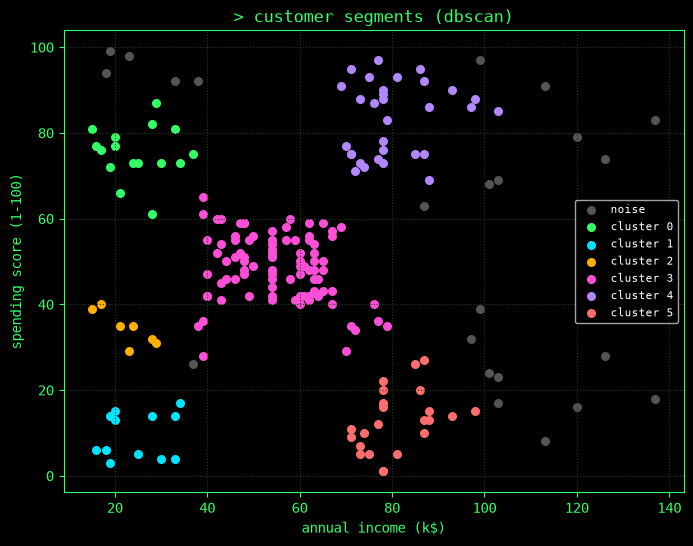

> K-MEANS VS DBSCAN                                               
┌─────────────────────────┬──────────┬──────────────┬────────────┐
│                         │ clusters │ noise points │ silhouette │
├─────────────────────────┼──────────┼──────────────┼────────────┤
│ K-Means                 │        5 │            0 │      0.555 │
│ DBSCAN (noise excluded) │        6 │           23 │      0.558 │
└─────────────────────────┴──────────┴──────────────┴────────────┘

In [11]:
dbscan = DBSCAN(eps=0.35, min_samples=5)
df['DBSCAN'] = dbscan.fit_predict(X_scaled)
n_clusters = df['DBSCAN'].nunique() - (1 if -1 in df['DBSCAN'].values else 0)
n_noise = (df['DBSCAN'] == -1).sum()
mask = df['DBSCAN'] != -1
db_sil = silhouette_score(X_scaled[mask], df.loc[mask, 'DBSCAN'])

plt.figure(figsize=(8, 6))
for label in sorted(df['DBSCAN'].unique()):
    group = df[df['DBSCAN'] == label]
    color = '#555555' if label == -1 else PALETTE[label % len(PALETTE)]
    plt.scatter(group['Income'], group['Spending'], s=30, color=color, label='noise' if label == -1 else f'cluster {label}')
plt.title('> customer segments (dbscan)')
plt.xlabel('annual income (k$)')
plt.ylabel('spending score (1-100)')
plt.legend(fontsize=8)
plt.show()

comparison = pd.DataFrame({
    'clusters': [best_k, n_clusters],
    'noise points': [0, n_noise],
    'silhouette': [scores.loc[best_k, 'silhouette'], db_sil],
}, index=['K-Means', 'DBSCAN (noise excluded)'])
term_table(comparison, 'K-MEANS VS DBSCAN')

## 8. Conclusions

- **Data:** 200 customers with no missing values or duplicates. Income and spending score were standardized before clustering.
- **Best number of clusters:** the silhouette score peaks at **k = 5 (0.555)**, which also matches the bend in the elbow curve.
- **The 5 segments (average spending per cluster):**
  - high income / high spending (39 customers, avg spending 82): the best target for premium offers
  - low income / high spending (22, avg 79): young (avg age 25), spend a lot despite low income
  - average income / average spending (81, avg 50): the largest, mainstream group
  - low income / low spending (23, avg 21): budget-conscious
  - high income / low spending (35, avg 17): can afford more but don't spend, a good target for marketing
- **DBSCAN (bonus):** found 6 dense groups and flagged 23 customers as outliers, with a similar silhouette (0.558, outliers excluded). K-Means is easier to use here because every customer gets a segment, while DBSCAN is useful for spotting unusual customers.
- **Takeaway:** income alone doesn't predict spending. Two very different groups earn the same high income, which is exactly what segmentation helps a mall see.